# Pre-trained Transformers

A pre-trained transformer has already read a huge amount of text. We do not train it from scratch: we **download it** and use it. In this notebook we work with **DistilBERT**, a small and fast version of BERT, through the **Hugging Face** libraries.

We go through six steps:

1. the **tokenizer**, that turns a text into the pieces and the numbers that the model reads;
2. the **contextual embeddings**: the same word gets different vectors in different sentences;
3. the **masked language model**, the task used to pre-train BERT;
4. the model as a **feature extractor**: a frozen encoder and a simple classifier on top;
5. **fine-tuning**: we train the whole model on our task;
6. **BERTopic**, a topic model built on top of a transformer encoder, on the same sentences.

The first part uses the **Stanford Sentiment Treebank** (Socher et al., 2013): sentences from movie reviews, labelled **positive** or **negative** by human annotators (the neutral ones are removed). The sentences are short, around 20 words.

In [1]:
# Run once if you are not using the course environment.
# %pip install -q torch transformers datasets scikit-learn pandas matplotlib bertopic

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification
from transformers import DataCollatorWithPadding, TrainingArguments, Trainer, pipeline, set_seed

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from umap import UMAP

In [3]:
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

MODEL_NAME = "distilbert-base-uncased"  # a small, fast version of BERT (66 million parameters)
print("device:", DEVICE)

device: mps


---
## The data

The dataset comes already split in **training**, **validation** and **test** sentences. Each sentence has a label: `1` for positive, `0` for negative. We compare the models on the validation sentences, and we use the **test sentences only at the end**.

In [4]:
train = pd.read_csv("Data/sst_train.csv")
valid = pd.read_csv("Data/sst_valid.csv")
test = pd.read_csv("Data/sst_test.csv")

print(len(train), "training,", len(valid), "validation,", len(test), "test sentences")
for text, label in zip(train.text[:3], train.label[:3]):
    print(label, text)

6920 training, 872 validation, 1821 test sentences
1 a stirring , funny and finally transporting re-imagining of beauty and the beast and 1930s horror films
0 apparently reassembled from the cutting-room floor of any given daytime soap .
0 they presume their audience wo n't sit still for a sociology lesson , however entertainingly presented , so they trot out the conventional science-fiction elements of bug-eyed monsters and futuristic women in skimpy clothes .


As a reference, a model that **ignores the order** of the words: TF-IDF and logistic regression.

In [5]:
tfidf = TfidfVectorizer(sublinear_tf=True)
T_train = tfidf.fit_transform(train.text)
baseline = LogisticRegression(max_iter=1000).fit(T_train, train.label)

baseline_valid = baseline.score(tfidf.transform(valid.text), valid.label)
baseline_test = baseline.score(tfidf.transform(test.text), test.label)
print("baseline validation accuracy:", round(baseline_valid, 3))

baseline validation accuracy: 0.788


---
## The tokenizer

A transformer reads **numbers**, not text. The tokenizer that comes with the model splits the text in **tokens** and gives an integer ID to each of them. DistilBERT uses **WordPiece**: frequent words are single tokens, rare words are split in **pieces** (the pieces that continue a word start with `##`).

In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

sentence = "The movie was unbelievably entertaining, but not a masterpiece."
print(tokenizer.tokenize(sentence))

['the', 'movie', 'was', 'un', '##bel', '##ie', '##va', '##bly', 'entertaining', ',', 'but', 'not', 'a', 'masterpiece', '.']


In [7]:
print(tokenizer.tokenize("electroencephalography"))

['electro', '##ence', '##pha', '##log', '##raphy']


To feed the model, the tokenizer also adds two **special tokens**, `[CLS]` at the beginning and `[SEP]` at the end, and converts the tokens to IDs.

In [8]:
encoded = tokenizer(sentence)
print(encoded["input_ids"])
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"]))

[101, 1996, 3185, 2001, 4895, 8671, 2666, 3567, 6321, 14036, 1010, 2021, 2025, 1037, 17743, 1012, 102]
['[CLS]', 'the', 'movie', 'was', 'un', '##bel', '##ie', '##va', '##bly', 'entertaining', ',', 'but', 'not', 'a', 'masterpiece', '.', '[SEP]']


Sentences have different lengths, but the model reads **batches**. With `padding=True` the shorter sentences are filled with the special token `[PAD]`, and the **attention mask** tells the model which positions are real tokens (`1`) and which are padding (`0`).

In [9]:
batch = tokenizer(["a good movie", sentence], padding=True, return_tensors="pt")
print(batch["input_ids"])
print(batch["attention_mask"])

tensor([[  101,  1037,  2204,  3185,   102,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0],
        [  101,  1996,  3185,  2001,  4895,  8671,  2666,  3567,  6321, 14036,
          1010,  2021,  2025,  1037, 17743,  1012,   102]])
tensor([[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])


---
## Contextual embeddings

We load the **pre-trained encoder**. The first time, the model is downloaded from the Hugging Face hub (about 270 MB, an internet connection is needed). It has 6 transformer blocks and gives, for every token, a vector of 768 numbers.

In [10]:
model = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE)

print("parameters:", sum(p.numel() for p in model.parameters()))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


parameters: 66362880


The same word has the same static embedding everywhere, but a transformer **reads the whole sentence**. We look at the vector of the word *bank* in three sentences: one about a river, two about money.

In [11]:
sentences = ["She sat on the bank of the river.",
             "He deposited the money at the bank.",
             "The bank approved the loan."]

inputs = tokenizer(sentences, padding=True, return_tensors="pt").to(DEVICE)
with torch.no_grad():
    outputs = model(**inputs)

hidden = outputs.last_hidden_state  # one vector for every token of every sentence
print(hidden.shape)

torch.Size([3, 11, 768])


In [12]:
positions = [tokenizer.convert_ids_to_tokens(ids).index("bank") for ids in inputs["input_ids"]]  # where "bank" is
bank = torch.stack([hidden[i, positions[i]] for i in range(3)])  # the three vectors of "bank"

similarity = torch.nn.functional.cosine_similarity(bank[:, None], bank[None, :], dim=-1)
names = ["river", "money 1", "money 2"]
pd.DataFrame(similarity.cpu().numpy(), index=names, columns=names).round(2)

,river,money 1,money 2
river,1.00,0.65,0.57
money 1,0.65,1.00,0.88
money 2,0.57,0.88,1.00


The vector of *bank* changes with the sentence. The two sentences about money are very close to each other (0.88), and the one about the river is farther from both (0.65 and 0.57). The word and its input embedding are the same in the three sentences: the difference comes from the **context**, which the attention layers mix into the vector. The exact numbers can change a little with the model and the device.

---
## Masked language modeling

BERT is pre-trained with a game: some tokens of a text are hidden with `[MASK]`, and the model must **guess them** from the words on both sides. The pipeline `fill-mask` lets us play it.

In [13]:
fill_mask = pipeline("fill-mask", model=MODEL_NAME, device=DEVICE)

results = fill_mask("The movie was really [MASK].", top_k=5)
pd.DataFrame(results)[["token_str", "score"]].round(3)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

,token_str,score
0,good,0.068
1,funny,0.061
2,bad,0.053
3,scary,0.046
4,entertaining,0.042


In [14]:
results = fill_mask("Paris is the [MASK] of France.", top_k=5)
pd.DataFrame(results)[["token_str", "score"]].round(3)

,token_str,score
0,capital,0.982
1,birthplace,0.003
2,northernmost,0.001
3,centre,0.001
4,southernmost,0.001


In the first sentence many words fit (*good*, *funny*, *bad*, *scary*, *entertaining*), and none is very probable: the pre-training does not know whether our review is positive or negative. In the second sentence the model is almost sure (*capital*, 0.98). To guess a hidden word the model must use the words on **both sides**, and this is a signal that comes from raw text, with no labels: it is how BERT learns the language.

---
## The encoder as a feature extractor

First way to use the model on our task: we **freeze** it. The vector of the `[CLS]` token, the first one, works as a **summary of the sentence**, and we use it as the input of a simple classifier. The pipeline `feature-extraction` runs the encoder on all the sentences, in batches.

In [15]:
extractor = pipeline("feature-extraction", model=MODEL_NAME, device=DEVICE)

out_train = extractor(list(train.text), batch_size=64, return_tensors=True, tokenize_kwargs={"truncation": True})
out_valid = extractor(list(valid.text), batch_size=64, return_tensors=True, tokenize_kwargs={"truncation": True})
out_test = extractor(list(test.text), batch_size=64, return_tensors=True, tokenize_kwargs={"truncation": True})

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [16]:
X_train = np.stack([o[0, 0].numpy() for o in out_train])  # the vector of [CLS] for every sentence
X_valid = np.stack([o[0, 0].numpy() for o in out_valid])
X_test = np.stack([o[0, 0].numpy() for o in out_test])

print(X_train.shape)

(6920, 768)


In [17]:
clf = LogisticRegression(max_iter=1000).fit(X_train, train.label)

features_valid = clf.score(X_valid, valid.label)
features_test = clf.score(X_test, test.label)
print("validation accuracy:", round(features_valid, 3))

validation accuracy: 0.859


With no training of the transformer, a logistic regression on the vector of `[CLS]` reaches a validation accuracy of 0.86, against 0.79 of TF-IDF. The frozen encoder already knows a lot about the language, much more than 6,920 sentences can teach.

---
## Fine-tuning

Second way: we **train the whole model** on our task. We put a small **classification head** on top of the encoder, and all the weights are updated with a **small learning rate**, so that the model keeps what it learned in pre-training. The `Trainer` of Hugging Face runs the training loop for us.

First we tokenize the sentences. The `Dataset` of the `datasets` library applies the tokenizer to all of them.

In [18]:
if DEVICE == "cpu":
    N_TRAIN, EPOCHS = 2000, 2  # on a CPU we use fewer sentences, to keep the training short
else:
    N_TRAIN, EPOCHS = len(train), 3

train_ds = Dataset.from_pandas(train.sample(N_TRAIN, random_state=0), preserve_index=False)
valid_ds = Dataset.from_pandas(valid, preserve_index=False)
test_ds = Dataset.from_pandas(test, preserve_index=False)

train_ds = train_ds.map(lambda batch: tokenizer(batch["text"], truncation=True), batched=True)
valid_ds = valid_ds.map(lambda batch: tokenizer(batch["text"], truncation=True), batched=True)
test_ds = test_ds.map(lambda batch: tokenizer(batch["text"], truncation=True), batched=True)

train_ds = train_ds.rename_column("label", "labels")
valid_ds = valid_ds.rename_column("label", "labels")
test_ds = test_ds.rename_column("label", "labels")

print(train_ds)

Map:   0%|          | 0/6920 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Map:   0%|          | 0/1821 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 6920
})


Then the model: the same encoder, with a **new linear layer** on top that gives two scores, one for each class. The layer starts from random weights, and this is why the library warns that some weights are newly initialized.

In [19]:
set_seed(0)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "negative", 1: "positive"},
    label2id={"negative": 0, "positive": 1},
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


The `TrainingArguments` collect the hyperparameters: the number of epochs, the batch size, the learning rate (the usual values for BERT are between `2e-5` and `5e-5`), and when to measure the loss and the accuracy on the validation sentences.

In [20]:
training_args = TrainingArguments(
    output_dir="distilbert-sst",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="steps",
    eval_steps=50,
    logging_steps=50,
    save_strategy="no",
    report_to="none",
    disable_tqdm=True,
    seed=0,
)

The `Trainer` needs the model, the arguments, the datasets, a **data collator** that pads every batch to the length of its longest sentence, and a small function that computes the accuracy from the scores.

In [21]:
def compute_metrics(eval_pred):
    scores, labels = eval_pred
    return {"accuracy": (scores.argmax(axis=-1) == labels).mean()}

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset={"train": train_ds.select(range(len(valid_ds))), "valid": valid_ds},
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)

In [22]:
%%time
trainer.train()

{'loss': '0.5623', 'grad_norm': '3.447', 'learning_rate': '1.849e-05', 'epoch': '0.2304'}
{'eval_train_loss': '0.358', 'eval_train_accuracy': '0.8624', 'eval_train_runtime': '1.666', 'eval_train_samples_per_second': '523.3', 'eval_train_steps_per_second': '8.402', 'epoch': '0.2304'}
{'eval_valid_loss': '0.3627', 'eval_valid_accuracy': '0.8555', 'eval_valid_runtime': '1.484', 'eval_valid_samples_per_second': '587.4', 'eval_valid_steps_per_second': '9.431', 'epoch': '0.2304'}
{'loss': '0.3528', 'grad_norm': '9.059', 'learning_rate': '1.696e-05', 'epoch': '0.4608'}
{'eval_train_loss': '0.2836', 'eval_train_accuracy': '0.9014', 'eval_train_runtime': '1.463', 'eval_train_samples_per_second': '596', 'eval_train_steps_per_second': '9.569', 'epoch': '0.4608'}
{'eval_valid_loss': '0.3119', 'eval_valid_accuracy': '0.8647', 'eval_valid_runtime': '1.352', 'eval_valid_samples_per_second': '644.8', 'eval_valid_steps_per_second': '10.35', 'epoch': '0.4608'}
{'loss': '0.3327', 'grad_norm': '5.113', 'l

TrainOutput(global_step=651, training_loss=0.23532936372973037, metrics={'train_runtime': 280.7383, 'train_samples_per_second': 73.948, 'train_steps_per_second': 2.319, 'train_loss': 0.23532936372973037, 'epoch': 3.0})

The `Trainer` keeps a log of the training: we plot the **loss** and the **accuracy**, on the training and on the validation sentences, during the training.

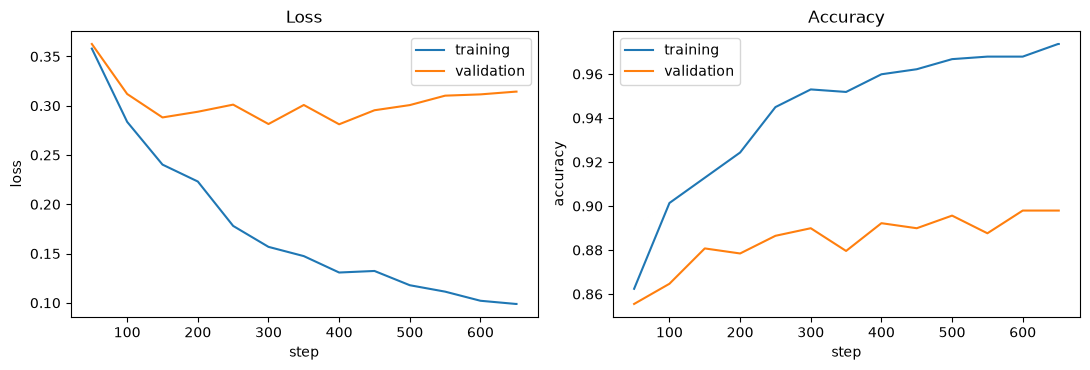

In [23]:
log = trainer.state.log_history

train_steps = [x["step"] for x in log if "eval_train_loss" in x]
train_loss = [x["eval_train_loss"] for x in log if "eval_train_loss" in x]
train_accuracy = [x["eval_train_accuracy"] for x in log if "eval_train_accuracy" in x]
valid_steps = [x["step"] for x in log if "eval_valid_loss" in x]
valid_loss = [x["eval_valid_loss"] for x in log if "eval_valid_loss" in x]
valid_accuracy = [x["eval_valid_accuracy"] for x in log if "eval_valid_accuracy" in x]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].plot(train_steps, train_loss, label="training")
axes[0].plot(valid_steps, valid_loss, label="validation")
axes[0].set(xlabel="step", ylabel="loss", title="Loss")
axes[0].legend()

axes[1].plot(train_steps, train_accuracy, label="training")
axes[1].plot(valid_steps, valid_accuracy, label="validation")
axes[1].set(xlabel="step", ylabel="accuracy", title="Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [24]:
finetuned_valid = trainer.evaluate(valid_ds)["eval_accuracy"]
finetuned_test = trainer.evaluate(test_ds)["eval_accuracy"]
print("validation accuracy:", round(finetuned_valid, 3))

{'eval_loss': '0.3143', 'eval_accuracy': '0.8979', 'eval_runtime': '1.422', 'eval_samples_per_second': '613.1', 'eval_steps_per_second': '9.843', 'epoch': '3'}
{'eval_loss': '0.2772', 'eval_accuracy': '0.9023', 'eval_runtime': '3.097', 'eval_samples_per_second': '588', 'eval_steps_per_second': '9.364', 'epoch': '3'}
validation accuracy: 0.898


Fine-tuning gives the best result so far: about 0.90 on the validation sentences. In the plot the training loss keeps going down while the validation loss stays around 0.3: after about one epoch the model starts to overfit, even if the accuracy still improves a little. A few epochs and a small learning rate are enough, because the model already knows the language and we only adapt it.

The fine-tuned model can be used like any pipeline. Words like **not** change the meaning of the next ones, so we try some sentences that we write.

In [25]:
classifier = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer, device=DEVICE)

new_sentences = ["a good movie", "not a good movie", "a bad movie", "not a bad movie", "the movie is not good at all"]
pd.DataFrame(classifier(new_sentences), index=new_sentences).round(3)

,label,score
a good movie,positive,0.993
not a good movie,negative,0.988
a bad movie,negative,0.989
not a bad movie,positive,0.778
the movie is not good at all,negative,0.989


The fine-tuned model handles the negations: *not a good movie* is negative, and *not a bad movie* is positive, even if with a lower confidence. It reads every word in its context, so *not* changes the meaning of the next word. The numbers change a little from run to run.

---
## The three models on the test sentences

We compare the three models on the same sentences, with the accuracy computed before.

In [26]:
comparison = pd.DataFrame({
    "model": ["TF-IDF + logistic regression", "frozen DistilBERT + logistic regression", "fine-tuned DistilBERT"],
    "validation": [baseline_valid, features_valid, finetuned_valid],
    "test": [baseline_test, features_test, finetuned_test],
})
comparison.round(3)

,model,validation,test
0,TF-IDF + logistic regression,0.788,0.796
1,frozen DistilBERT + logistic regression,0.859,0.859
2,fine-tuned DistilBERT,0.898,0.902


Every step brings an improvement: about 6 points on the test sentences from TF-IDF to the frozen encoder, and 4 more with fine-tuning. The frozen encoder is cheap (a few seconds of feature extraction and one logistic regression). Fine-tuning takes minutes and is much faster on a GPU, but it is the best. The test accuracies are close to the validation ones, so we did not overfit the validation sentences.

---
## Topics with BERTopic

A transformer encoder is useful for more than classification. **BERTopic** finds the **topics** of a corpus, and it works in four steps:

1. a pre-trained **sentence encoder** gives a vector to every document;
2. **UMAP** reduces the vectors to a few dimensions;
3. **HDBSCAN** finds the groups of documents with similar vectors. This is a **clustering**: the documents that do not belong to any group are the **outliers**, and they go in the topic `-1`;
4. every group is described by its **most characteristic words**, with a TF-IDF computed on the groups instead of on the documents (**c-TF-IDF**). This turns the clusters into **topics**: a list of words that a person can read.

So is BERTopic a clustering method or a topic model? **Both**: a clustering of the embeddings of the documents, followed by a description of the clusters. Compared with a classical topic model such as LDA, it uses the **meaning** of the sentences (the embeddings) and not only the counts of the words, every document belongs to **one** topic (LDA gives a mixture of topics), and the number of topics is found by the algorithm.

We use the **same sentences** of this notebook, and we **throw the labels away**: BERTopic does not use them. The first time, the sentence encoder is downloaded.

In [27]:
docs = [text.replace("-lrb-", "(").replace("-rrb-", ")") for text in train.text]  # the corpus writes the brackets as -lrb- and -rrb-

encoder = SentenceTransformer("all-MiniLM-L6-v2")  # a small transformer, trained to give similar vectors to similar sentences
embeddings = encoder.encode(docs, show_progress_bar=False)

print(embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

(6920, 384)


We choose how to reduce the vectors (UMAP, with a fixed seed to get the same topics at every run), and the minimum number of sentences of a topic. The `CountVectorizer` removes the English stop words from the descriptions of the topics.

In [28]:
topic_model = BERTopic(
    embedding_model=encoder,
    umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=0),
    vectorizer_model=CountVectorizer(stop_words="english"),
    min_topic_size=30,
)
topics, probabilities = topic_model.fit_transform(docs, embeddings)

Every topic has a number and a name made of its most characteristic words. The topic `-1` collects the outliers. The last column is the share of positive sentences in the topic: BERTopic never saw the labels, but we have them, and we can use them to check what the topics are.

In [29]:
info = topic_model.get_topic_info()[["Topic", "Count", "Name"]]
share = pd.DataFrame({"Topic": topics, "positive": train.label}).groupby("Topic").positive.mean().round(2)
info["positive share"] = info.Topic.map(share)

info.head(14)

,Topic,Count,Name,positive share
0,-1,3973,-1_like_film_movie_story,0.51
1,0,1103,0_film_movie_movies_good,0.47
2,1,243,1_cast_performances_actors_performance,0.71
3,2,203,2_kids_family_disney_parents,0.63
4,3,198,3_thriller_horror_scary_suspense,0.48
5,4,125,4_comedy_romantic_black_parody,0.54
6,5,123,5_does_bad_hate_wrong,0.33
7,6,113,6_pretentious_pointless_fluffy_unlikable,0.37
8,7,99,7_characters_story_character_storytelling,0.41
9,8,80,8_minutes_hours_time_hour,0.22


BERTopic finds topics about the **subject** of the review: the cast and the performances (1), family films (2), thrillers and horror (3), comedies and romances (4), the screenplay (12), the length of the film (8: *minutes, hours*). Other topics follow the **sentiment** more than the subject: *bad, hate, wrong* (5) and *pretentious, pointless, unlikable* (6) are mostly negative (33% and 37% of positive sentences), while the topic about the cast (1) is mostly positive (71%). Topic 0 (*film, movie, movies, good*) is generic. More than half of the sentences (3,973 out of 6,920) are outliers: the sentences are short and generic, and many of them do not belong to a clear group.

To see the clusters we reduce the vectors to **two** dimensions with UMAP, and we draw one point for every sentence with **plotly**. Move the mouse on the points to read the sentences. The outliers are grey.

In [30]:
reduced = UMAP(n_neighbors=15, n_components=2, min_dist=0.0, metric="cosine", random_state=0).fit_transform(embeddings)

names = info.set_index("Topic").Name
points = pd.DataFrame({"x": reduced[:, 0], "y": reduced[:, 1], "topic": [names[t] for t in topics], "sentence": docs})

px.scatter(points, x="x", y="y", color="topic", hover_data=["sentence"], color_discrete_map={names[-1]: "lightgrey"}, width=900, height=650)

Every point is a sentence and every colour is a topic. There is a big generic group at the top and many small compact groups around it, where the topics are specific, while the outliers (in grey) fill the space between the groups. The two axes of UMAP have no meaning by themselves: only the distances between nearby points do.

---
# Exercises

- **Tokenizer.** Tokenize a sentence in another language, a sentence with emojis and a word with a typo. How many pieces does the tokenizer use?
- **Context.** Repeat the *bank* experiment with other ambiguous words (*bat*, *light*, *match*). Do the vectors of the same word become more similar or less similar than the vectors of two different words?
- **Masked words.** Try `fill-mask` on your own sentences. Where does the model fail? Try a mask in the middle of a long sentence, and a sentence with two `[MASK]`.
- **Pooling.** Replace the vector of `[CLS]` with the **mean** of the vectors of all the tokens (use `o[0].mean(axis=0)`). Is the logistic regression better?
- **Fine-tuning.** Change the learning rate (`1e-5`, `5e-5`, `1e-4`), the number of epochs or the size of the training set. When does the model overfit?
- **Frozen layers.** Freeze the encoder during the fine-tuning (`for p in model.distilbert.parameters(): p.requires_grad = False`) and train only the head. What changes?
- **Another model.** Use `bert-base-uncased` instead of DistilBERT. Is it better? How much longer does it take?
- **Topics.** Change `min_topic_size` (for example 15 and 60), or use `nr_topics=10`. How do the topics and the number of outliers change? Look at `topic_model.reduce_outliers` to move the outliers to the closest topic.